In [ ]:
# 5. Build a Feedforward Neural Network for ASL alphabet classification. 
# Evaluate the trained model using test data and generate a confusion 
# matrix to identify correctly and incorrectly classified alphabet gestures. 

In [1]:
# Import required libraries

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [2]:
# Step 1: Load training and testing datasets

train_data = pd.read_csv("sign_mnist_train.csv")
test_data = pd.read_csv("sign_mnist_test.csv")


In [3]:
# Display the shape of training and testing datasets

print("Training Dataset Shape:", train_data.shape)
print("Testing Dataset Shape:", test_data.shape)

Training Dataset Shape: (27455, 785)
Testing Dataset Shape: (7172, 785)


In [4]:
# Step 2: Separate labels and pixel values

X_train = train_data.drop("label", axis=1).values
y_train = train_data["label"].values

X_test = test_data.drop("label", axis=1).values
y_test = test_data["label"].values

In [5]:
# Step 3: Convert labels into 24 consecutive classes

classes = np.sort(np.unique(y_train))

# Create mapping for original labels to consecutive numbers
label_map = {label: index for index, label in enumerate(classes)}

y_train = np.array([label_map[label] for label in y_train])
y_test = np.array([label_map[label] for label in y_test])

# Store alphabet names for confusion matrix display
alphabet_labels = [chr(label + 65) for label in classes]

In [6]:
# Step 4: Normalize pixel values between 0 and 1

X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

In [7]:
# Step 5: Flatten images (28 x 28 = 784)

X_train = X_train.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)

print("Training Input Shape:", X_train.shape)
print("Testing Input Shape:", X_test.shape)

Training Input Shape: (27455, 784)
Testing Input Shape: (7172, 784)


In [8]:
# Step 6: Split training data into training and validation sets

X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

In [9]:
# Step 7: Build Feedforward Neural Network

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),

    # First hidden layer
    tf.keras.layers.Dense(256, activation="relu"),

    # Second hidden layer
    tf.keras.layers.Dense(128, activation="relu"),

    # Third hidden layer
    tf.keras.layers.Dense(64, activation="relu"),

    # Output layer for 24 alphabet classes
    tf.keras.layers.Dense(24, activation="softmax")
])

In [10]:
# Step 8: Compile the model

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [11]:
# Step 9: Display model summary

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 256)                 │         200,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 24)                  │           1,560 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 243,672 (951.84 KB)

 Trainable params: 243,672 (951.84 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# Step 10: Train the model

history = model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=128,
    validation_data=(X_val, y_val)
)

Epoch 1/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 6s 23ms/step - accuracy: 0.2611 - loss: 2.4220 - val_accuracy: 0.4637 - val_loss: 1.7603
Epoch 2/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.5193 - loss: 1.5224 - val_accuracy: 0.6214 - val_loss: 1.2448
Epoch 3/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.6456 - loss: 1.1235 - val_accuracy: 0.7119 - val_loss: 0.9245
Epoch 4/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.7296 - loss: 0.8573 - val_accuracy: 0.7696 - val_loss: 0.7082
Epoch 5/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.7902 - loss: 0.6673 - val_accuracy: 0.8266 - val_loss: 0.5475
Epoch 6/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.8372 - loss: 0.5194 - val_accuracy: 0.8629 - val_loss: 0.4315
Epoch 7/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.8763 - loss: 0.4050 - val_accuracy: 0.8987 - val_loss: 0.3270
Epoch 8/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.9027 - loss: 0.3212 - val_accu

In [13]:
# Step 11: Evaluate the model using testing dataset

test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Testing Loss:", test_loss)
print("Testing Accuracy: {:.2f}%".format(test_accuracy * 100))

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7658 - loss: 1.1320
Testing Loss: 1.1319631338119507
Testing Accuracy: 76.58%


In [14]:
# Step 12: Predict labels for testing dataset

y_pred = model.predict(X_test)

# Convert predicted probabilities into class labels
y_pred = np.argmax(y_pred, axis=1)

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


In [15]:
# Step 13: Generate confusion matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[311   0   0   0   0   0   0   0   0   0   0   0  20   0   0   0   0   0
    0   0   0   0   0   0]
 [  0 388   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0  41   0   3   0   0]
 [  0   0 289   0   0  21   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0]
 [  0  19   0 190   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   4   0  32   0]
 [  0   0   0   0 498   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0]
 [  0   0   0   0   0 212   0   0   0   0   0   0   0   0   0   0   0   0
   20   0   0  14   1   0]
 [  0   0   0   0   0   0 281   0   0   0   0   0  15  14   0  25   0   0
   12   0   0   0   1   0]
 [  0   1   0   0   0   0  45 390   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0]
 [  0   0   0   0   1   0   0   0 245   0   5   0   0   0   0   0  16   0
    0   0   0   0   0  21]
 [  0   4   0   0   0   0   0   0  21 123   0   0   0   0   0   0  23  20

<Figure size 1200x1200 with 0 Axes>

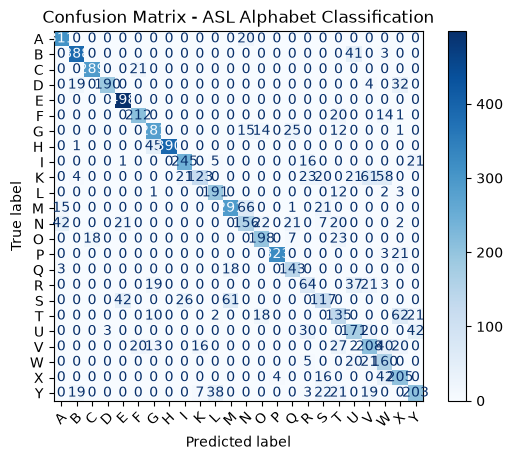

In [16]:
# Step 14: Display confusion matrix

plt.figure(figsize=(12, 12))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=alphabet_labels
)

disp.plot(cmap="Blues", xticks_rotation=45, values_format="d")

plt.title("Confusion Matrix - ASL Alphabet Classification")
plt.show()

In [17]:
# Step 15: Calculate correctly and incorrectly classified images

correct = np.trace(cm)
total = np.sum(cm)
incorrect = total - correct

print("Total Test Images:", total)
print("Correctly Classified:", correct)
print("Incorrectly Classified:", incorrect)
print("Accuracy: {:.2f}%".format((correct / total) * 100))

Total Test Images: 7172
Correctly Classified: 5492
Incorrectly Classified: 1680
Accuracy: 76.58%
